# Исследование объявлений о продаже квартир

В вашем распоряжении данные сервиса Яндекс.Недвижимость — архив объявлений о продаже квартир в Санкт-Петербурге и соседних населённых пунктов за несколько лет. Нужно научиться определять рыночную стоимость объектов недвижимости. Ваша задача — установить параметры. Это позволит построить автоматизированную систему: она отследит аномалии и мошенническую деятельность. 

По каждой квартире на продажу доступны два вида данных. Первые вписаны пользователем, вторые — получены автоматически на основе картографических данных. Например, расстояние до центра, аэропорта, ближайшего парка и водоёма. 

### Откройте файл с данными и изучите общую информацию. 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23699 entries, 0 to 23698
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   total_images          23699 non-null  int64  
 1   last_price            23699 non-null  float64
 2   total_area            23699 non-null  float64
 3   first_day_exposition  23699 non-null  object 
 4   rooms                 23699 non-null  int64  
 5   ceiling_height        14504 non-null  float64
 6   floors_total          23613 non-null  float64
 7   living_area           21796 non-null  float64
 8   floor                 23699 non-null  int64  
 9   is_apartment          2775 non-null   object 
 10  studio                23699 non-null  bool   
 11  open_plan             23699 non-null  bool   
 12  kitchen_area          21421 non-null  float64
 13  balcony               12180 non-null  float64
 14  locality_name         23650 non-null  object 
 15  airports_nearest   

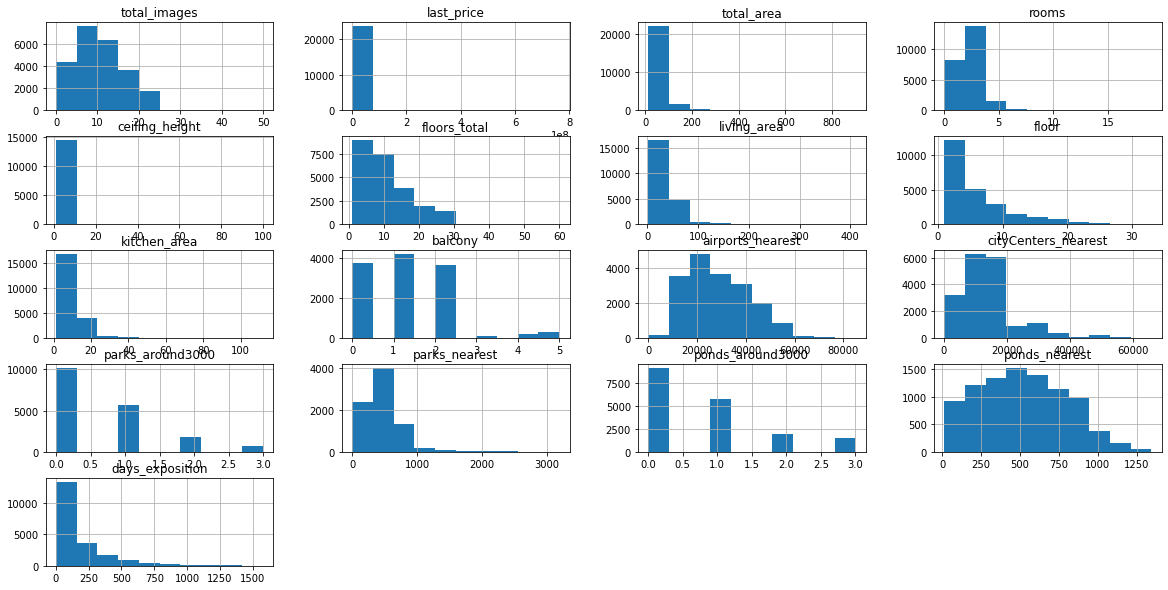

In [151]:
import pandas as pd

data = pd.read_csv('/datasets/real_estate_data.csv', sep='\t')
data.info()
print(data.head())
print(data.hist(figsize=(20,10)))#смотрим распределение

### Предобработка данных

In [152]:
print(data.isna().sum())#ищем пустые значения

total_images                0
last_price                  0
total_area                  0
first_day_exposition        0
rooms                       0
ceiling_height           9195
floors_total               86
living_area              1903
floor                       0
is_apartment            20924
studio                      0
open_plan                   0
kitchen_area             2278
balcony                 11519
locality_name              49
airports_nearest         5542
cityCenters_nearest      5519
parks_around3000         5518
parks_nearest           15620
ponds_around3000         5518
ponds_nearest           14589
days_exposition          3181
dtype: int64


# Обработка пустых значений
* ceiling_height — высота потолков (м)
Медианное значение соответсвует примерно значению высоты потолков. Заменяем все пустые значения на медианное.
* * Вероятно составители анкеты не знали точное значение
* floors_total — всего этажей в доме
Всего 86 пустых значений из примерно 24000 можно удалить.
* * Возможно это одноэтажные дома или с непонятным количеством этажей
* living_area — жилая площадь в квадратных метрах (м²)
Пустые заполняем медианным значением.
* * Вероятно составители анкеты не знали точное значение
* is_apartment — апартаменты (булев тип)
Вероятно пустые значения это false.
* * Из-за большого количества вероятно, что во многих пунктах False превратился в nan
* kitchen_area — площадь кухни в квадратных метрах (м²)
Пустые заполняем медианным значением.
* * Вероятно составители анкеты не знали точное значение
* balcony — число балконов
Пустые заполняем медианным значением.
* * Вероятно часть было 0, часть не были уверены в точном значении(например соедененный балкон, изначально было 2 сейчас 1
* locality_name — название населённого пункта
48 из 24000 можно убрать.
* * Вероятно определить принадлженость к населенному пункту невозможно
* airports_nearest — расстояние до ближайшего аэропорта в метрах (м)
Пустые заполняем медианным значением.
* * Вероятно составители анкеты не знали точное значение
* cityCenters_nearest — расстояние до центра города (м)
Пустые заполняем медианным значением.
* * Вероятно составители анкеты не знали точное значение
* parks_around3000 — число парков в радиусе 3 км
Пустые заполняем медианным значением.
* * Вероятно составители анкеты не знали точное значение
* parks_nearest — расстояние до ближайшего парка (м)
Пустые заполняем медианным значением.
* * Вероятно составители анкеты не знали точное значение
* ponds_around3000 — число водоёмов в радиусе 3 км
Пустые заполняем медианным значением.
* * Вероятно составители анкеты не знали точное значение
* ponds_nearest — расстояние до ближайшего водоёма (м)
Пустые заполняем медианным значением.
* * Вероятно составители анкеты не знали точное значение
* days_exposition — сколько дней было размещено объявление (от публикации до снятия)
Пустые заполняем медианным значением.
* * вероятно была потерена или изменена дата подачи

In [153]:
#медианные значения:
med=['ceiling_height','living_area','is_apartment','kitchen_area',
     'balcony','airports_nearest','cityCenters_nearest','parks_around3000',
    'parks_nearest','ponds_around3000','ponds_nearest','days_exposition']
for array in med:
    data.loc[data[array].isna(),array] = data[array].median()
#удаление:
delete=['floors_total','locality_name']
for array in delete:
    data=data.dropna(subset=[array])

Проверяем, что все пустые значения исчезли

In [154]:
print(data.isna().sum())#ищем пустые значения
data.info()#смотрим типы данных

total_images            0
last_price              0
total_area              0
first_day_exposition    0
rooms                   0
ceiling_height          0
floors_total            0
living_area             0
floor                   0
is_apartment            0
studio                  0
open_plan               0
kitchen_area            0
balcony                 0
locality_name           0
airports_nearest        0
cityCenters_nearest     0
parks_around3000        0
parks_nearest           0
ponds_around3000        0
ponds_nearest           0
days_exposition         0
dtype: int64
<class 'pandas.core.frame.DataFrame'>
Int64Index: 23565 entries, 0 to 23698
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   total_images          23565 non-null  int64  
 1   last_price            23565 non-null  float64
 2   total_area            23565 non-null  float64
 3   first_day_exposition  23565 non-null  object 


# Изменяем тип данных
Разберем все столбцы по типам данных, которыми они должны быть.
`float` airports_nearest — расстояние до ближайшего аэропорта в метрах (м)
`int` balcony — число балконов
`float` ceiling_height — высота потолков (м)
`float` cityCenters_nearest — расстояние до центра города (м)
`int` days_exposition — сколько дней было размещено объявление (от публикации до снятия)
`data` first_day_exposition — дата публикации
`int` floor — этаж
`int`floors_total — всего этажей в доме
`bool`is_apartment — апартаменты (булев тип)
`float`kitchen_area — площадь кухни в квадратных метрах (м²)
`float`last_price — цена на момент снятия с публикации
`float`living_area — жилая площадь в квадратных метрах (м²)
`obj`locality_name — название населённого пункта
`bool`open_plan — свободная планировка (булев тип)
`float`parks_around3000 — число парков в радиусе 3 км
`float`parks_nearest — расстояние до ближайшего парка (м)
`float`ponds_around3000 — число водоёмов в радиусе 3 км
`float`ponds_nearest — расстояние до ближайшего водоёма (м)
`int`rooms — число комнат
`bool`studio — квартира-студия (булев тип)
`float`total_area — общая площадь квартиры в квадратных метрах (м²)
`int`total_images — число фотографий квартиры в объявлении
Изменяем все для удобства

In [155]:
#float
change_type = ['airports_nearest','ceiling_height','cityCenters_nearest',
            'kitchen_area','last_price','living_area','parks_around3000',
             'parks_nearest','ponds_around3000','ponds_nearest','total_area']
for array in change_type:
    data[array] = data[array].astype('float')
#bool
change_type = ['is_apartment','open_plan','studio']
for array in change_type:
    data[array] = data[array].astype('bool')
#int
change_type = ['balcony','days_exposition','floor',
               'floors_total','rooms','total_images']
for array in change_type:
    data[array] = data[array].astype('int')
data['first_day_exposition']=pd.to_datetime(data['first_day_exposition'], format='%Y.%m.%d')#оставляем только дату
data.info()#проверяем типы

<class 'pandas.core.frame.DataFrame'>
Int64Index: 23565 entries, 0 to 23698
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   total_images          23565 non-null  int64         
 1   last_price            23565 non-null  float64       
 2   total_area            23565 non-null  float64       
 3   first_day_exposition  23565 non-null  datetime64[ns]
 4   rooms                 23565 non-null  int64         
 5   ceiling_height        23565 non-null  float64       
 6   floors_total          23565 non-null  int64         
 7   living_area           23565 non-null  float64       
 8   floor                 23565 non-null  int64         
 9   is_apartment          23565 non-null  bool          
 10  studio                23565 non-null  bool          
 11  open_plan             23565 non-null  bool          
 12  kitchen_area          23565 non-null  float64       
 13  balcony         

# Неявные дубликаты в названиях населённых пунктов
Приводем все названия кк нижнему регистру, меняем ё на е, поселок городского типа и городской поселок на поселок. Основные дубликаты мы убрали.

In [156]:
data['locality_name'] = data['locality_name'].str.lower()
data['locality_name'] = data['locality_name'].str.replace('ё','е')
data['locality_name'] = data['locality_name'].str.replace('поселок городского типа','поселок')
data['locality_name'] = data['locality_name'].str.replace('городской поселок','поселок')
print(data['locality_name'].unique())

['санкт-петербург' 'поселок шушары' 'поселок янино-1' 'поселок парголово'
 'поселок мурино' 'ломоносов' 'сертолово' 'петергоф' 'пушкин'
 'деревня кудрово' 'коммунар' 'колпино' 'поселок красный бор' 'гатчина'
 'деревня федоровское' 'выборг' 'кронштадт' 'кировск'
 'деревня новое девяткино' 'поселок металлострой' 'поселок лебяжье'
 'поселок сиверский' 'поселок молодцово' 'поселок кузьмоловский'
 'садовое товарищество новая ропша' 'павловск' 'деревня пикколово'
 'всеволожск' 'волхов' 'кингисепп' 'приозерск' 'сестрорецк'
 'деревня куттузи' 'поселок аннино' 'поселок ефимовский'
 'поселок плодовое' 'деревня заклинье' 'поселок торковичи'
 'поселок первомайское' 'красное село' 'поселок понтонный' 'сясьстрой'
 'деревня старая' 'деревня лесколово' 'поселок новый свет' 'сланцы'
 'село путилово' 'ивангород' 'мурино' 'шлиссельбург' 'никольское'
 'зеленогорск' 'сосновый бор' 'деревня оржицы' 'деревня кальтино'
 'кудрово' 'поселок романовка' 'поселок бугры' 'поселок рощино' 'кириши'
 'луга' 'волосово'

### Устранение редких и выбивающихся значений (аномалии) во всех столбцах
Для изучения зависимостей мы должны рассматривать наиболее востребованные варианты. Для этого нужно отбросить редкие и выбивающиеся. Основными критериями при выборе квартир считается общая площадь, жилая площадь, площадь кухни, количество комнат, всего этажей, высота потолков. На основе этих критериев уберем сильно выделяющиеся
* total_area < 150
* living_area < 100
* kitchen_area < 20
* rooms < 6
* floors_total < 30
* ceiling_height < 4

Теперь рассмотрим значения выбивающиеся(нереалистичные)
* last_price < 20000000
* rooms != 0
* ceiling_height > 2
* balcony < 4

Уберем квартиры расположенные очень далеко от важных объектов: парк, аэропорт, центр города и водоемы. Так как спрос на такие квартиры очень низок 
* airports_nearest < 60000 
* cityCenters_nearest < 40000 
* parks_nearest < 1000 
* ponds_nearest < 1250

Мы привели все гистограммы к адекватному виду. Следовательно убрали все редкие и выбивающиеся значения 

array([[<AxesSubplot:title={'center':'total_images'}>,
        <AxesSubplot:title={'center':'last_price'}>,
        <AxesSubplot:title={'center':'total_area'}>,
        <AxesSubplot:title={'center':'first_day_exposition'}>],
       [<AxesSubplot:title={'center':'rooms'}>,
        <AxesSubplot:title={'center':'ceiling_height'}>,
        <AxesSubplot:title={'center':'floors_total'}>,
        <AxesSubplot:title={'center':'living_area'}>],
       [<AxesSubplot:title={'center':'floor'}>,
        <AxesSubplot:title={'center':'kitchen_area'}>,
        <AxesSubplot:title={'center':'balcony'}>,
        <AxesSubplot:title={'center':'airports_nearest'}>],
       [<AxesSubplot:title={'center':'cityCenters_nearest'}>,
        <AxesSubplot:title={'center':'parks_around3000'}>,
        <AxesSubplot:title={'center':'parks_nearest'}>,
        <AxesSubplot:title={'center':'ponds_around3000'}>],
       [<AxesSubplot:title={'center':'ponds_nearest'}>,
        <AxesSubplot:title={'center':'days_exposition'

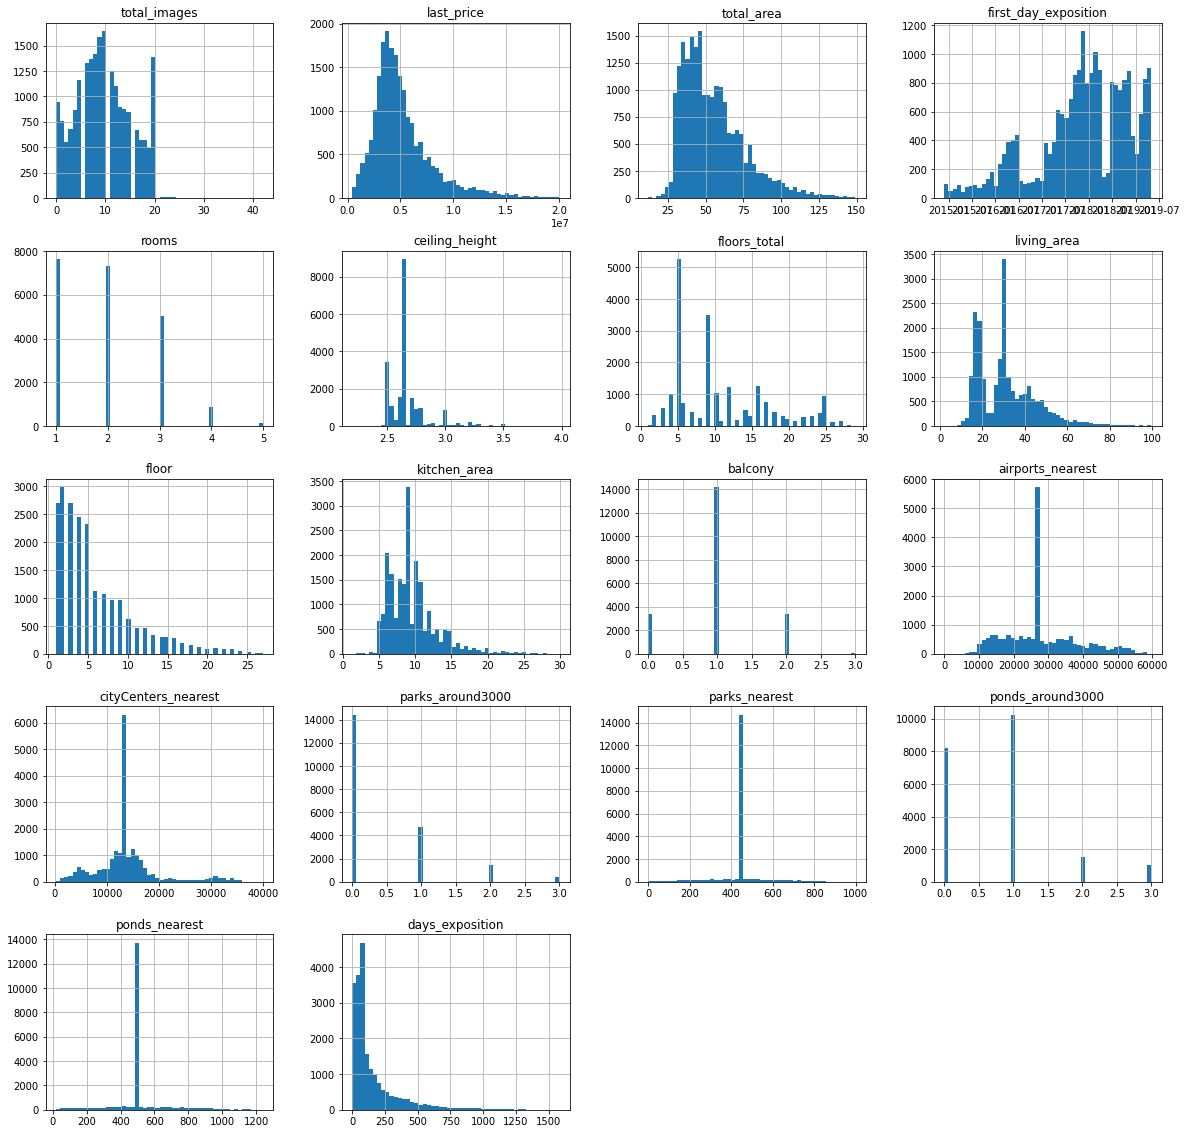

In [157]:
#print(data.describe())
data = data.query('total_area < 150 and living_area < 100 and kitchen_area < 30 and rooms <6 and floors_total < 30 and ceiling_height < 4')
data = data.query('last_price < 20000000 and rooms != 0 and ceiling_height > 2 and balcony < 4')
data = data.query('airports_nearest < 60000 and cityCenters_nearest < 40000 and parks_nearest < 1000 and ponds_nearest < 1250')
data.hist(bins=50,figsize=(20,20))

### Посчитайте и добавьте в таблицу новые столбцы

* Цена одного квадратного метра
* День публикации объявления (0 - понедельник, 1 - вторник и т.д.)
* Месяц публикации объявления
* Год публикации объявления
* Тип этажа квартиры (значения — «первый», «последний», «другой»)
* Расстояние в км до центра города

In [184]:
data['price_for_meter'] = round(data['last_price']/data['total_area'])
data['day'] = data['first_day_exposition'].dt.weekday
data['month'] = data['first_day_exposition'].dt.month
data['year'] = data['first_day_exposition'].dt.year
data['type_floor']='другой'
data['type_floor'] = data['type_floor'].where(data['floor'] != 1, 'первый')
data['type_floor'] = data['type_floor'].where(data['floor'] != data['floors_total'],'последний')
data['cityCenters_nearest_km']=round(data['cityCenters_nearest']/1000)
data.head()

,total_images,last_price,total_area,first_day_exposition,rooms,ceiling_height,floors_total,living_area,floor,is_apartment,...,parks_nearest,ponds_around3000,ponds_nearest,days_exposition,price_for_meter,day,month,year,type_floor,cityCenters_nearest_km
0,20,13000000.0,108.0,2019-03-07,3,2.70,16,51.0,8,False,...,482.0,2.0,755.0,95,120370.0,3,3,2019,другой,16.0
1,7,3350000.0,40.4,2018-12-04,1,2.65,11,18.6,1,False,...,455.0,0.0,502.0,81,82921.0,1,12,2018,первый,19.0
2,10,5196000.0,56.0,2015-08-20,2,2.65,5,34.3,4,False,...,90.0,2.0,574.0,558,92786.0,3,8,2015,другой,14.0
5,10,2890000.0,30.4,2018-09-10,1,2.65,12,14.4,5,False,...,455.0,1.0,502.0,55,95066.0,0,9,2018,другой,13.0
6,6,3700000.0,37.3,2017-11-02,1,2.65,26,10.6,6,False,...,455.0,0.0,502.0,155,99196.0,3,11,2017,другой,19.0


### Проведите исследовательский анализ данных

Изучите, как быстро продавались квартиры (столбец days_exposition). Этот параметр показывает, сколько дней «висело» каждое объявление.

95.0
count    20999.000000
mean       164.956141
std        201.057840
min          1.000000
25%         45.000000
50%         95.000000
75%        193.000000
max       1580.000000
Name: days_exposition, dtype: float64


<AxesSubplot:>

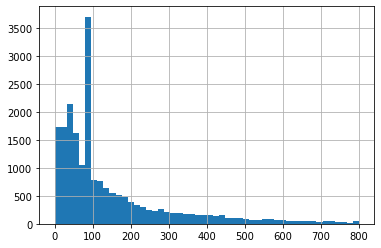

In [191]:
print(data['days_exposition'].describe())
data['days_exposition'].hist(bins=50, range=(0,800))

Медиана 95, среднее 164. Среднее время продажь примерно 95 дней, быстрые около 45, долгие в районе 193 дней.

"Какие факторы больше всего влияют на общую (полную) стоимость объекта? Постройте графики, которые покажут зависимость цены от указанных ниже параметров. Для подготовки данных перед визуализацией вы можете использовать сводные таблицы."

        - общей площади;
        - жилой площади;
        - площади кухни;
        - количество комнат;
        - типа этажа, на котором расположена квартира (первый, последний, другой);
        - даты размещения (день недели, месяц, год);

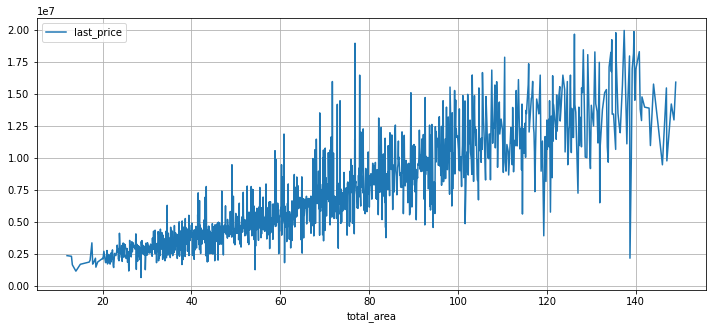

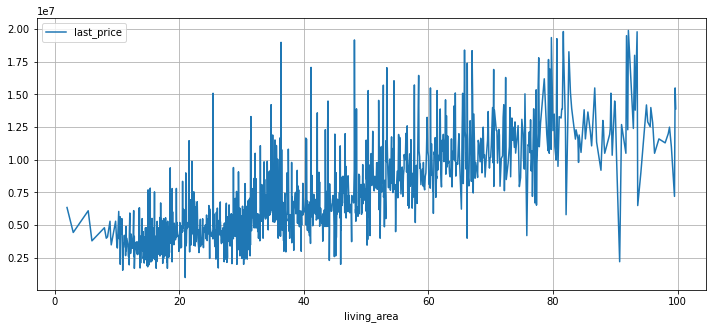

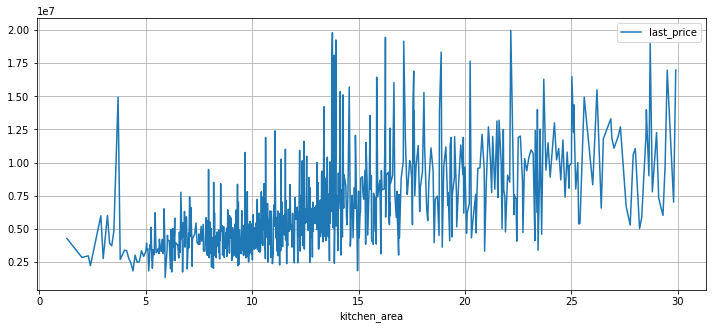

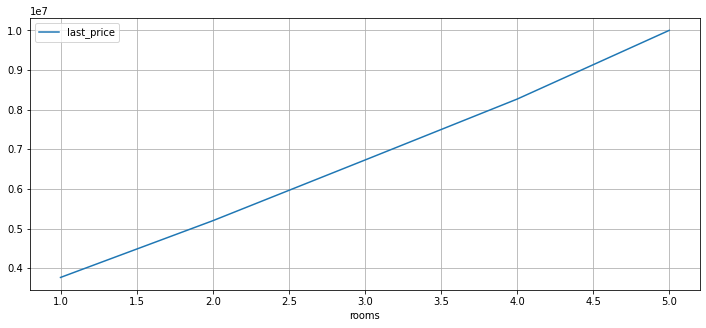

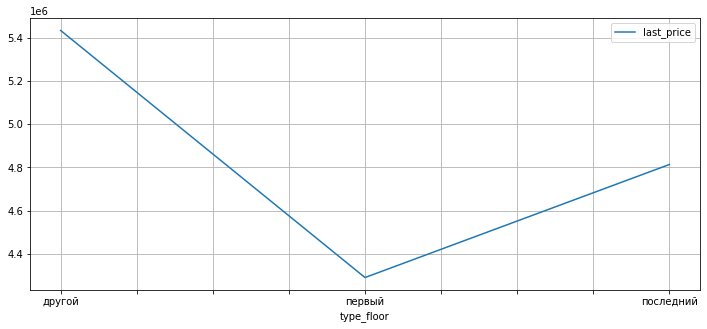

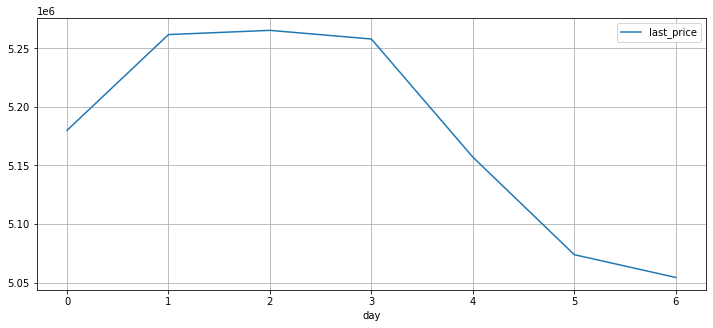

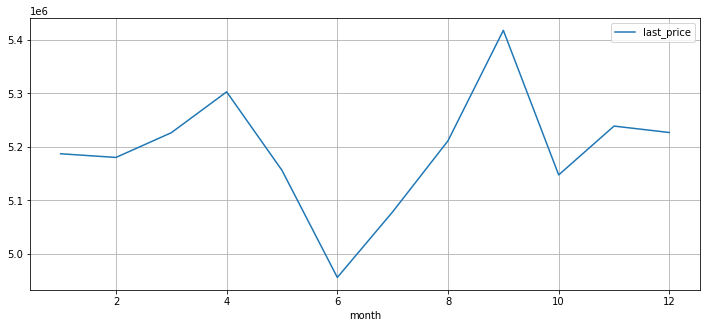

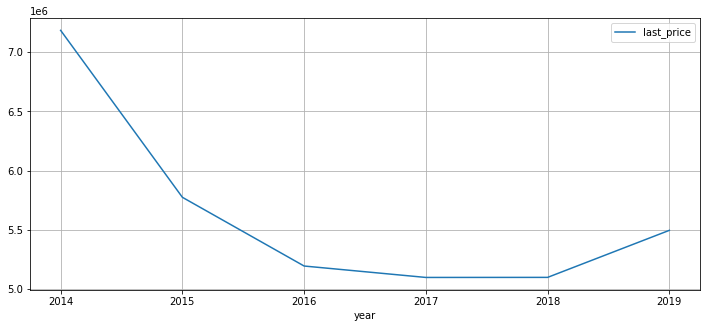

In [222]:
marks=['total_area','living_area','kitchen_area','rooms','type_floor','day', 'month','year']
for array in marks:
    data.pivot_table(index=array,values='last_price',aggfunc='mean').plot(grid=True, figsize=(12,5))


Из полученных графиков сделаем выводы о цене в зависимотси от:

        - общей площади; Прямая зависимость
        - жилой площади; Прямая зависимость
        - площади кухни; Прямая зависимость
        - количество комнат; Прямая зависимость
        - типа этажа, на котором расположена квартира (первый, последний, другой); Цена на первый этаж значительно ниже, на последний выше, чем на нижний, но значительно ниже чем на другой.
        - даты размещения (день недели, месяц, год); В начале недели цена на квартиры в среднем выше чем в конец. Дорогие квартиры в основном покупают весной и осенью, летом обычно покупают квартиры дешевле. За последние года цены на квартиры упали, но в 2018-2019 году снова начался рост

Посчитайте среднюю цену одного квадратного метра в 10 населённых пунктах с наибольшим числом объявлений. Выделите населённые пункты с самой высокой и низкой стоимостью квадратного метра. Эти данные можно найти по имени в столбце `locality_name`.

In [260]:
meters=(data.pivot_table(index='locality_name',values='price_for_meter',aggfunc=('mean','count'))
 .sort_values(by='count',ascending=False))
print('Цена топ-10 по количеству объявлений:\n',meters.head(10))
print('Минимальная цена:\n',meters.loc[meters['mean']==meters['mean'].min()])
print('Максимальная цена:\n',meters.loc[meters['mean']==meters['mean'].max()])

Цена топ-10 по количеству объявлений:
                    count           mean
locality_name                          
санкт-петербург    13766  107925.810039
поселок мурино       511   85145.788650
поселок шушары       424   78515.832547
всеволожск           372   67006.744624
пушкин               343  101654.632653
колпино              315   75147.006349
гатчина              293   68761.313993
поселок парголово    292   93037.500000
деревня кудрово      277   92615.036101
выборг               227   58177.180617
Минимальная цена:
                     count          mean
locality_name                          
деревня старополье      3  11206.333333
Максимальная цена:
                count      mean
locality_name                 
кронштадт          1  111471.0


Ранее вы посчитали расстояние до центра в километрах. Теперь выделите квартиры в Санкт-Петербурге с помощью столбца `locality_name` и вычислите среднюю цену каждого километра. Опишите, как стоимость объектов зависит от расстояния до центра города.

<AxesSubplot:xlabel='cityCenters_nearest_km'>

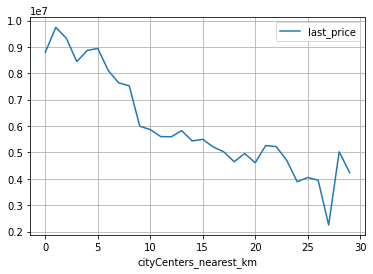

In [263]:
data.query('locality_name=="санкт-петербург"').pivot_table(index='cityCenters_nearest_km',values='last_price',aggfunc='mean').plot(grid=True)

Из графика видно, что в среднем чем ближе к центру тем дороже квартиры.

### Общий вывод

В этом проекте мы выполнили предобработку данных и их анализ. 

В изначальных данных было много пропусков особенно в некоторых пунктах. Чтобы избежать этого можно выставить изначальные значения(базовые), которые будут автоматически ставится, когда других нет.

Во втором разделе мы добавляли пункты. Такие как цена за кв.м. и растояния до центра в км очень важны, думаю стоит их добавить в автоматическое вычисление. Остальные пункты мы добавили для удобства своего анализа.

* В вопросах мы изучили зависимость на рынке. 
* Основные моменты это средняя продажа квартир за 100 дней, это 3 месяца, достаточно длительный срок.
* В начале недели цена выше, так как в этот период основная работа идет, а такие квартиры чаще всего продают не владельцы, а с помощью других лиц.
* Такие параметры как квадратура жилая, кухня и общая и количество комнат прямо влияют на цену квартиры.
* Важен этаж, квартиры на первом и последнем значительно дешевле, это легко объяснить. На первом на уровне с окнами улица, на последнем над головой крыша.
* Так же на цену очень влият приблеженность к центру города.
